# Water well experimentation
Install the package with `pip install -e ".[dev]"` first. All modeling logic lives in `water_wells`. Run from the repository root or its notebooks directory.

In [1]:
from pathlib import Path
from water_wells import (DataConfig, DataLoader, TrainingConfig,
                         TrainingPipeline, ModelEvaluator)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
loader = DataLoader(DataConfig(data_dir=ROOT))
X, y = loader.load_training()
X.shape, y.value_counts()

((59400, 40),
 status_group
 functional                 32259
 non functional             22824
 functional needs repair     4317
 Name: count, dtype: int64)

In [2]:
X.columns

Index(['id', 'amount_tsh', 'date_recorded', 'funder', 'gps_height',
       'installer', 'longitude', 'latitude', 'wpt_name', 'num_private',
       'basin', 'subvillage', 'region', 'region_code', 'district_code', 'lga',
       'ward', 'population', 'public_meeting', 'recorded_by',
       'scheme_management', 'scheme_name', 'permit', 'construction_year',
       'extraction_type', 'extraction_type_group', 'extraction_type_class',
       'management', 'management_group', 'payment', 'payment_type',
       'water_quality', 'quality_group', 'quantity', 'quantity_group',
       'source', 'source_type', 'source_class', 'waterpoint_type',
       'waterpoint_type_group'],
      dtype='str')

## Split raw data, then fit
Only training rows fit the geographic reference, imputers, encoders, and model. The original notebook used 500 estimators and a 25% validation fraction.

In [ ]:
config = TrainingConfig(model_path=ROOT / "models/water_well_model.joblib")
pipeline = TrainingPipeline(
    config,
    population_raster=ROOT / "tza_pop_2026_CN_1km_R2025A_UA_v1.tif",
    cache_dir=ROOT / "data/processed/population",
    data_mode="auto",
)
holdout_regions = ["Morogoro"]
X_train, X_valid, X_holdout, y_train, y_valid, y_holdout = pipeline.split(X, y, holdout_regions=holdout_regions)
pipeline.fit(X_train, y_train)

In [4]:
evaluator = ModelEvaluator()
predictions = pipeline.predict(X_valid)
evaluator.metrics(y_valid, predictions)

{'accuracy': 0.7895622895622896,
 'precision': 0.7921307144160723,
 'recall': 0.7895622895622896,
 'f1': 0.7750386819927673}

In [5]:
import pandas as pd

# Use the same held-out rows as XGBoost; fit baselines on training labels only.
random_predictions = evaluator.baseline_predictions(
    X_train, y_train, X_valid,
    strategy="stratified", random_state=config.random_seed,
)
majority_predictions = evaluator.baseline_predictions(
    X_train, y_train, X_valid, strategy="most_frequent",
)
comparison_df = pd.DataFrame.from_dict({
    "xgboost": evaluator.metrics(y_valid, predictions),
    "random_baseline": evaluator.metrics(y_valid, random_predictions),
    "majority_baseline": evaluator.metrics(y_valid, majority_predictions),
}, orient="index")
comparison_df


,accuracy,precision,recall,f1
xgboost,0.789562,0.792131,0.789562,0.775039
random_baseline,0.451852,0.451378,0.451852,0.451613
majority_baseline,0.543098,0.294955,0.543098,0.382290


In [ ]:
from IPython.display import display
import pandas as pd

# Evaluate the unseen geographic region separately from validation.
holdout_results_df = pipeline.predict_wells(X_holdout)
holdout_results_df["actual_status"] = y_holdout
holdout_results_df["region"] = X_holdout["region"]
holdout_predictions = holdout_results_df["predicted_status"]
holdout_metrics_df = pd.DataFrame(
    [evaluator.metrics(y_holdout, holdout_predictions)],
    index=["geographic_holdout"],
)
display(holdout_metrics_df)
print(evaluator.classification_report(y_holdout, holdout_predictions))
holdout_results_df.head()


In [6]:
print(evaluator.classification_report(y_valid, predictions))
evaluator.confusion_matrix(y_valid, predictions)

                         precision    recall  f1-score   support

             functional       0.76      0.92      0.84      8065
functional needs repair       0.69      0.22      0.33      1079
         non functional       0.85      0.71      0.77      5706

               accuracy                           0.79     14850
              macro avg       0.77      0.62      0.65     14850
           weighted avg       0.79      0.79      0.78     14850



,functional,functional needs repair,non functional
functional,7455,67,543
functional needs repair,698,236,145
non functional,1633,39,4034


In [15]:
print(evaluator.classification_report(y_valid, random_predictions))
evaluator.confusion_matrix(y_valid, random_predictions)

                         precision    recall  f1-score   support

             functional       0.55      0.55      0.55      8065
functional needs repair       0.07      0.07      0.07      1079
         non functional       0.39      0.39      0.39      5706

               accuracy                           0.45     14850
              macro avg       0.34      0.34      0.34     14850
           weighted avg       0.45      0.45      0.45     14850



,functional,functional needs repair,non functional
functional,4410,563,3092
functional needs repair,579,78,422
non functional,3071,413,2222


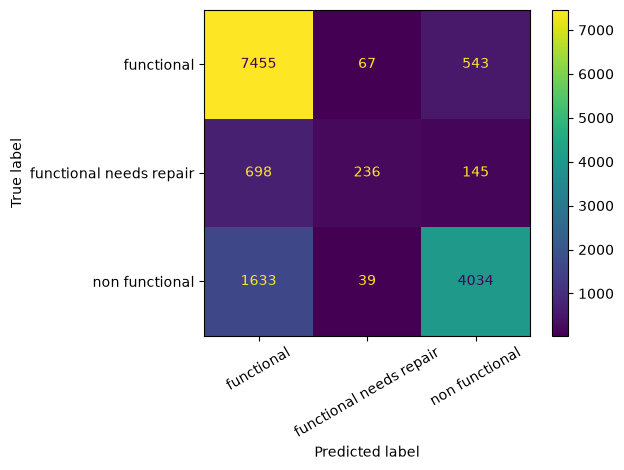

In [7]:
evaluator.plot_confusion_matrix(y_valid, predictions);

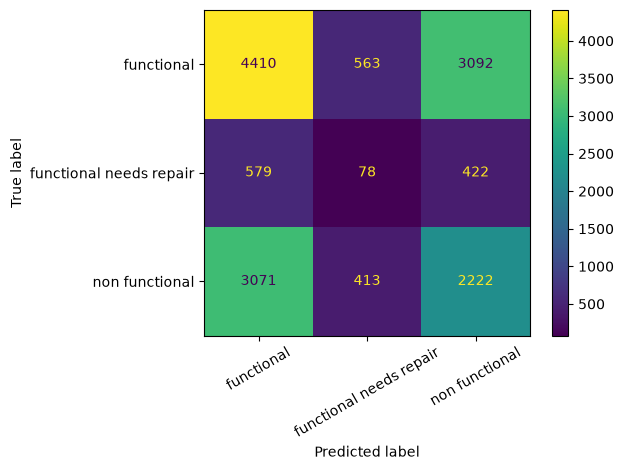

In [16]:
evaluator.plot_confusion_matrix(y_valid, random_predictions);



In [8]:
evaluator.plot_feature_importance(pipeline, top_n=500);

In [9]:
pipeline.predict_proba(X_valid.head())

,functional,functional needs repair,non functional
44614,0.155255,0.015639,0.829107
42868,0.448348,0.299304,0.252348
24507,0.825684,0.060970,0.113346
35407,0.324477,0.088596,0.586927
48257,0.792238,0.038629,0.169132


In [10]:
pipeline.predict_wells(X_valid.head())

,id,latitude,longitude,predicted_status,probability_functional,probability_needs_repair,probability_non_functional
44614,49391,-1.242508,33.911895,non functional,0.155255,0.015639,0.829107
42868,12638,-1.480412,31.740816,functional,0.448348,0.299304,0.252348
24507,41709,-3.853344,35.483507,functional,0.825684,0.060970,0.113346
35407,7072,-4.464789,38.077040,non functional,0.324477,0.088596,0.586927
48257,15294,-4.424756,33.435959,functional,0.792238,0.038629,0.169132


## Save and reload
Load serialized artifacts only from trusted sources. This saves the training-split model; fit a fresh pipeline on all labeled rows after finalizing your experiment to make a final inference artifact.

In [11]:
pipeline.save()
restored = TrainingPipeline.load(config.model_path)
assert (restored.predict(X_valid.head()) == pipeline.predict(X_valid.head())).all()

## New unlabeled wells
Use the original feature schema. `predict_wells` preserves IDs, row order, index, and raw coordinates.

In [12]:
# new_wells = loader.load_features("data/raw/test_values.csv")
# results = restored.predict_wells(new_wells)
# results.to_csv(ROOT / "data/processed/predictions.csv", index=False)

## Cross-validation
`TrainingPipeline` is sklearn compatible. Every fold fits its own spatial reference and encoder; use raw features and readable target labels.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
import pandas as pd

# Geographic holdout stays outside every cross-validation fold.
X_cv = pd.concat([X_train, X_valid])
y_cv = pd.concat([y_train, y_valid])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=config.random_seed)
scores = cross_val_score(clone(pipeline), X_cv, y_cv, cv=cv, scoring="accuracy")

In [14]:
scores

array([0.79131313, 0.78545455, 0.78732323])